In [2]:
## Bibliotecas usadas

from pathlib import Path
import re
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import loadmat
from scipy.optimize import minimize
from scipy import sparse

In [3]:
## Leitura dos dados

dados2 = loadmat('dado2.mat')
dados3 = Path("dado3.txt")
Y = np.asarray(dados2["Y"], dtype=float)
R = np.asarray(dados2["R"])

## Definindo funções

def ler_titulos(caminho):
    for codificacao in ("utf-8-sig", "latin-1"):
        try:
            linhas = caminho.read_text(encoding=codificacao).splitlines()
            break
        except UnicodeDecodeError:
            continue
    titulos = []
    for linha in linhas:
        nome = linha.strip()
        if not nome:
            continue
        nome = re.sub(r"^\d+\s+", "", nome)
        titulos.append(nome)
    return titulos

titulos = ler_titulos(dados3)
n_filmes, n_usuarios = Y.shape


print(f"Filmes: {n_filmes:,} | Usuários: {n_usuarios:,}")
print(f"Avaliações observadas: {R.sum():,} ({100 * R.mean():.2f}% da matriz)")
print(f"Atributos latentes escolhidos: {100}")

Filmes: 1,682 | Usuários: 943
Avaliações observadas: 100,000 (6.30% da matriz)
Atributos latentes escolhidos: 100


In [4]:
rng = np.random.default_rng(42)
X_inicial = rng.normal(loc=0, scale=0.1, size=(n_filmes, 100))
Theta_inicial = rng.normal(loc=0, scale=0.1, size=(n_usuarios, 100))

linhas_obs, colunas_obs = np.nonzero(R)
notas_obs = Y[linhas_obs, colunas_obs]

def empacotar(X, Theta):
    return np.concatenate((X.ravel(), Theta.ravel()))

def desempacotar(parametros):
    separador = n_filmes * 100
    X_atual = parametros[:separador].reshape(n_filmes, 100)
    Theta_atual = parametros[separador:].reshape(n_usuarios, 100)
    return X_atual, Theta_atual

def custo_e_gradiente(parametros):
    X_atual, Theta_atual = desempacotar(parametros)
    # Produto interno apenas nos pares com avaliação observada.
    previstos_obs = np.einsum(
        "ij,ij->i", X_atual[linhas_obs], Theta_atual[colunas_obs]
    )
    erro_obs = previstos_obs - notas_obs
    custo = 0.5 * np.dot(erro_obs, erro_obs)

    E = sparse.coo_matrix(
        (erro_obs, (linhas_obs, colunas_obs)),
        shape=(n_filmes, n_usuarios)
    ).tocsr()
    grad_X = E @ Theta_atual
    grad_Theta = E.T @ X_atual
    gradiente = empacotar(grad_X, grad_Theta)
    return custo, gradiente

parametros_iniciais = empacotar(X_inicial, Theta_inicial)
print(f"Número de parâmetros ajustáveis: {parametros_iniciais.size:,}")
print(f"Custo inicial: {custo_e_gradiente(parametros_iniciais)[0]:,.2f}")

Número de parâmetros ajustáveis: 262,500
Custo inicial: 686,751.66


In [5]:
historico_custo = [custo_e_gradiente(parametros_iniciais)[0]]

def registrar_iteracao(parametros):
    historico_custo.append(custo_e_gradiente(parametros)[0])

resultado = minimize(
    fun=custo_e_gradiente,
    x0=parametros_iniciais,
    method="CG",
    jac=True,
    callback=registrar_iteracao,
    options={"maxiter": 50, "gtol": 1e-4, "disp": False}
)

X, Theta = desempacotar(resultado.x)
print("Otimização:", resultado.message)
print("Convergência reportada pelo otimizador:", resultado.success)
print("Iterações realizadas:", resultado.nit)
print(f"Custo final: {resultado.fun:,.2f}")

Otimização: Maximum number of iterations has been exceeded.
Convergência reportada pelo otimizador: False
Iterações realizadas: 50
Custo final: 3,233.50


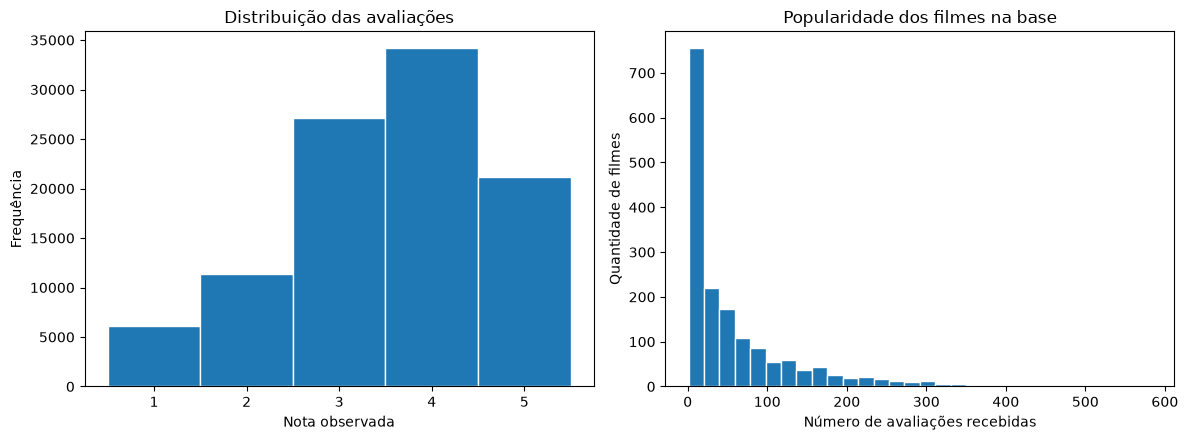

In [6]:
notas_observadas = Y[R == 1]
qtd_por_filme = R.sum(axis=1)
qtd_por_usuario = R.sum(axis=0)

fig, axs = plt.subplots(1, 2, figsize=(12, 4.5))
axs[0].hist(notas_observadas, bins=np.arange(0.5, 6.0, 1), edgecolor="white")
axs[0].set_xticks([1, 2, 3, 4, 5])
axs[0].set_xlabel("Nota observada")
axs[0].set_ylabel("Frequência")
axs[0].set_title("Distribuição das avaliações")

axs[1].hist(qtd_por_filme, bins=30, edgecolor="white")
axs[1].set_xlabel("Número de avaliações recebidas")
axs[1].set_ylabel("Quantidade de filmes")
axs[1].set_title("Popularidade dos filmes na base")

fig.tight_layout()
plt.show()

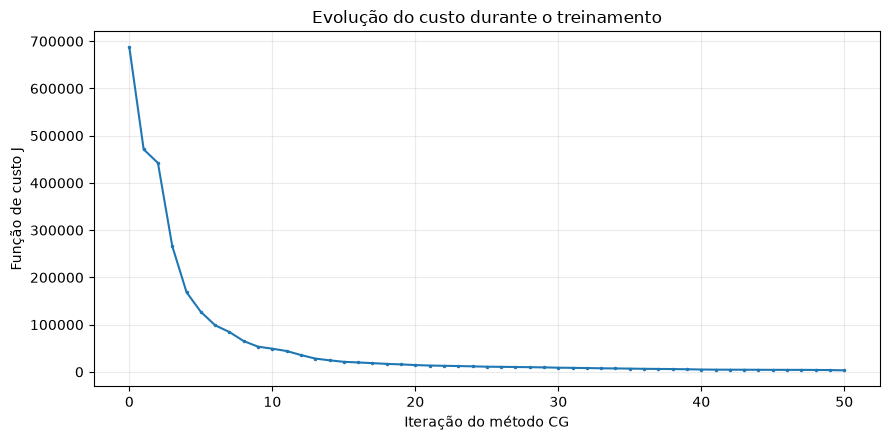

In [7]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(np.arange(len(historico_custo)), historico_custo, marker=".", markersize=3)
ax.set_xlabel("Iteração do método CG")
ax.set_ylabel("Função de custo J")
ax.set_title("Evolução do custo durante o treinamento")
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()

In [8]:
previsoes_observadas = np.einsum(
    'ij,ij->i', X[linhas_obs], Theta[colunas_obs], optimize=True
)
rmse_treino = np.sqrt(np.mean((previsoes_observadas - notas_obs)**2))

print('Dimensão teórica da matriz de previsões:', (n_filmes, n_usuarios))
print(f'RMSE nas avaliações observadas: {rmse_treino:.4f}')
print(f'Intervalo das previsões observadas: '
      f'[{previsoes_observadas.min():.2f}, {previsoes_observadas.max():.2f}]')

Dimensão teórica da matriz de previsões: (1682, 943)
RMSE nas avaliações observadas: 0.2543
Intervalo das previsões observadas: [0.09, 6.38]


In [9]:
medias_previstas = X @ Theta.mean(axis=0)
indices_top10 = np.argsort(-medias_previstas, kind='stable')[:10]

ranking = [(pos, titulos[i], float(medias_previstas[i]), int(qtd_por_filme[i]))
           for pos, i in enumerate(indices_top10, start=1)]
print('10 filmes com maiores notas médias previstas:')
for pos, nome, nota, quantidade in ranking:
    print(f'{pos:2d}. {nome} | Média prevista: {nota:.3f} | Notas observadas: {quantidade}')


10 filmes com maiores notas médias previstas:
 1. Star Wars (1977) | Média prevista: 4.265 | Notas observadas: 583
 2. Godfather, The (1972) | Média prevista: 4.082 | Notas observadas: 413
 3. Shawshank Redemption, The (1994) | Média prevista: 3.874 | Notas observadas: 283
 4. Fargo (1996) | Média prevista: 3.829 | Notas observadas: 508
 5. Titanic (1997) | Média prevista: 3.800 | Notas observadas: 350
 6. Schindler's List (1993) | Média prevista: 3.738 | Notas observadas: 298
 7. Silence of the Lambs, The (1991) | Média prevista: 3.710 | Notas observadas: 390
 8. Braveheart (1995) | Média prevista: 3.702 | Notas observadas: 297
 9. Usual Suspects, The (1995) | Média prevista: 3.700 | Notas observadas: 267
10. Godfather: Part II, The (1974) | Média prevista: 3.677 | Notas observadas: 209


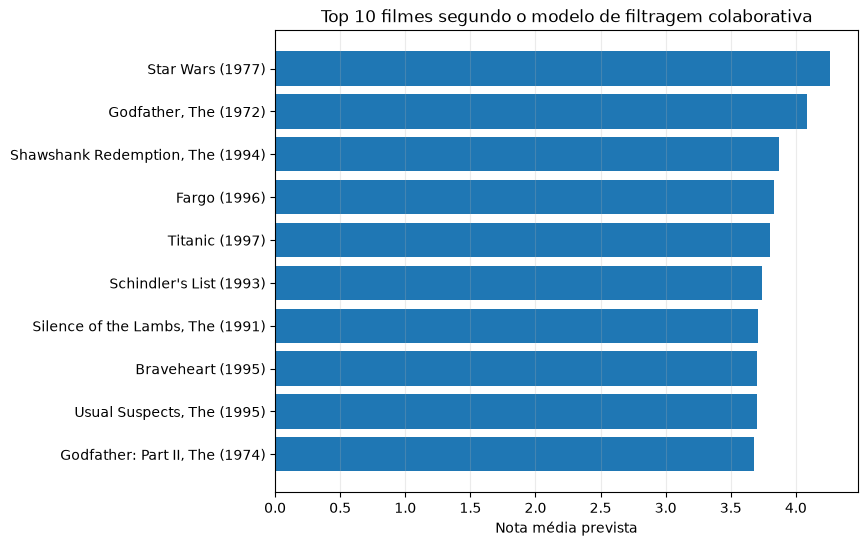

In [ ]:
## Ranking top 10 filmes

fig, ax = plt.subplots(figsize=(11, 6))
ordem_exibicao = ranking[::-1]


nomes = [item[1] for item in ordem_exibicao]
medias = [item[2] for item in ordem_exibicao]

ax.barh(nomes, medias)

ax.set_xlabel("Nota média prevista")
ax.set_title("Top 10 filmes segundo o modelo de filtragem colaborativa")
ax.grid(axis="x", alpha=0.25)

plt.subplots_adjust(left=0.37)
plt.show()